Cell 1 – Import libraries

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

Cell 2 – Upload dataset

In [2]:
from google.colab import files
uploaded = files.upload()

df = pd.read_csv("spam.csv", encoding="latin-1")

df.head()

Saving spam.csv to spam (1).csv


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


Cell 3 – Data cleaning

In [3]:
df = df[["v1", "v2"]]

df.columns = ["label", "message"]

df = df.dropna()

df = df.drop_duplicates()

print(df.head())
print("\nDataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset Shape: (5169, 2)

Missing Values:
label      0
message    0
dtype: int64


Cell 4 – Class distribution

label
ham     4516
spam     653
Name: count, dtype: int64

Percentage:
label
ham     87.366996
spam    12.633004
Name: proportion, dtype: float64


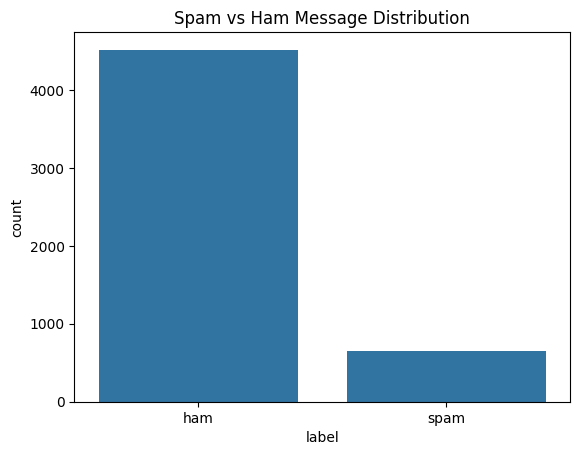

In [4]:
print(df["label"].value_counts())

print("\nPercentage:")
print(df["label"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="label")
plt.title("Spam vs Ham Message Distribution")
plt.show()

Cell 5 – Text preprocessing

In [5]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_message"] = df["message"].apply(clean_text)

df[["message", "clean_message"]].head()

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...


Cell 6 – Split the dataset

In [6]:
X = df["clean_message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4135
Testing samples: 1034


Cell 7 – TF-IDF explanation and models

TF-IDF converts text into numerical features. It gives more importance to words that are useful for identifying a message and less importance to words that appear frequently across many messages.

We'll train two models: Multinomial Naive Bayes and Logistic Regression.

In [7]:
nb_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2)
    )),
    ("model", MultinomialNB())
])

lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2)
    )),
    ("model", LogisticRegression(max_iter=1000))
])

nb_model.fit(X_train, y_train)
lr_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


Cell 8 – Model evaluation

In [8]:
models = {
    "Naive Bayes": nb_model,
    "Logistic Regression": lr_model
}

for name, model in models.items():
    predictions = model.predict(X_test)

    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, predictions))
    print(classification_report(y_test, predictions))


 Naive Bayes
Accuracy: 0.9516441005802708
              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       903
        spam       1.00      0.62      0.76       131

    accuracy                           0.95      1034
   macro avg       0.97      0.81      0.87      1034
weighted avg       0.95      0.95      0.95      1034


 Logistic Regression
Accuracy: 0.9429400386847195
              precision    recall  f1-score   support

         ham       0.94      1.00      0.97       903
        spam       0.99      0.56      0.71       131

    accuracy                           0.94      1034
   macro avg       0.96      0.78      0.84      1034
weighted avg       0.95      0.94      0.94      1034



Cell 9 – Confusion matrix

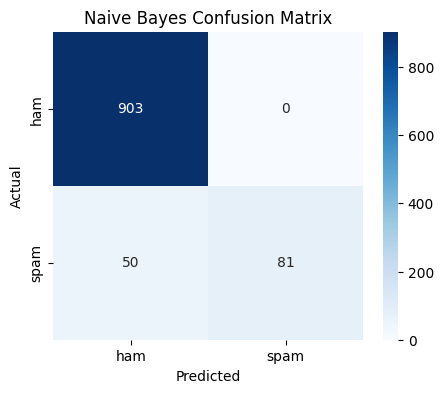

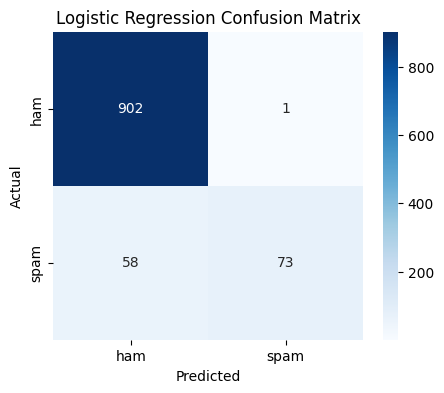

In [9]:
for name, model in models.items():
    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["ham", "spam"]
    )

    plt.figure(figsize=(5,4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["ham", "spam"],
        yticklabels=["ham", "spam"]
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

Cell 10 – Test a new message

In [10]:
test_message = ["Congratulations! You have won a free prize. Call now!"]

prediction = nb_model.predict(test_message)

print("Prediction:", prediction[0])

Prediction: spam


Cell 11 – Compare models

In [11]:
for name, model in models.items():
    predictions = model.predict(X_test)
    print(
        name,
        "Accuracy:",
        round(accuracy_score(y_test, predictions) * 100, 2),
        "%"
    )

Naive Bayes Accuracy: 95.16 %
Logistic Regression Accuracy: 94.29 %


Cell 12 – Save predictions

In [12]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": nb_model.predict(X_test)
})

results.to_csv("spam_detection_results.csv", index=False)

print("Results saved successfully!")

Results saved successfully!
